# 11A — Drill-to-NFL transfer matrix

**Hypothesis (S11A).** Some Combine drills contain movement information associated with *physically comparable* NFL movements beyond what the official timed tests capture.

**Design (fixed before reading any NFL value).** Cells = drill family × NFL demand with DECLARED physical overlap (11.0). Target = the demand's declared NFL quantity (`transfer_matrix.DEMAND_TARGETS`). Ladder on athlete-held-out folds: M0 context → M1 + official tests (+ the drill's own official time) → M2 + ≤ 3 PRESELECTED interpretable features → M3 + the whole feature family (ridge). Controls on SUPPORTED cells: wrong-drill features, random Gaussian projections, noncomparable interval, athlete-label permutation (declared primary cells only).

**Signature result.** The matrix *Combine drill → NFL demand → observed evidence*, every cell in one of six classes. An untested or underpowered cell is never shown as a zero effect.

**Prerequisites.** 11.0, 11B, 11C (same `RUN_MODE`).

In [1]:
RUN_MODE = 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
ALL_TARGETS = False           # True = also run the secondary target of every demand (more comparisons, all exploratory)
BY_POSITION = True            # repeat the SUPPORTED cells within each position that meets the support line

In [2]:
import sys
import os
import numpy as np
import polars as pl

print("Python:", sys.version)
print("Executable:", sys.executable)
print("NumPy:", np.__version__)
print("Polars:", pl.__version__)

print("NumPy test:", np.arange(5))
print("Environment OK")

Python: 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)]
Executable: c:\Users\myben\.conda\envs\nfl\python.exe
NumPy: 2.2.6
Polars: 2.0.0
NumPy test: [0 1 2 3 4]
Environment OK


In [3]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import DiscoveryStore
from nflbdb.research.advanced_movement.m11 import assemble as asm
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import evaluation as ev
from nflbdb.research.advanced_movement.m11 import figures as fg
from nflbdb.research.advanced_movement.m11 import reporting as rp
from nflbdb.research.advanced_movement.m11 import tournament as tn
from nflbdb.research.advanced_movement.m11 import transfer_matrix as tm
from nflbdb.research.advanced_movement.m11 import validation as v11

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = DiscoveryStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m11c.M11Config().for_mode(controls)
PROV = m11c.provenance('11A', controls, C)
W = store.write_frame
pooled = asm.foundation(store, 'm11_feasibility_pooled')
fm = asm.foundation(store, 'm11_feasibility_matrix')
athf = asm.foundation(store, 'm11_athlete_features')
targets_long = asm.foundation(store, 'm11_nfl_targets')
data = asm.linked_table(store)
folds = data['fold'].to_numpy()
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {data.height} linked athletes · {pooled.height} family × demand cells'))
checks = v11.run_all(v11.CHECKS_STATS)
display(checks)
v11.assert_all_passed(checks)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\data\config.py:264: UserWarning: polars was imported before configure_runtime(); POLARS_MAX_THREADS will not apply to this process. Restart the kernel and call configure_runtime() first.
  warnings.warn(


**Run mode: `full`** (FULL) · 387 linked athletes · 63 family × demand cells

check,status,detail
str,str,str
"""resampling_and_comparison""","""PASS""","""paired athlete bootstrap: null…"
"""pair_overlap_resampling""","""PASS""","""pair resampling is by athlete …"
"""mixed_model_and_twins""","""PASS""","""EM mixed model recovers slope …"


## 1 · Data availability and the preselected features

The preselected features (`combine_drills.PRESELECTED`) were declared from physics before any NFL value was read; they are not searched.

family,demand_id,overlap_confidence,shared_quantity,n_linked_supported,n_combine_athletes,feasibility
str,str,str,str,i64,i64,str
"""backpedal_transition""","""accel_low""","""none""","""""",142,183,"""UNSUPPORTED"""
"""backpedal_transition""","""accel_mid""","""none""","""""",121,183,"""UNSUPPORTED"""
"""backpedal_transition""","""braking""","""medium""","""deceleration of the backpedal""",133,183,"""SUPPORTED"""
"""backpedal_transition""","""reaccel_after_brake""","""medium""","""forward acceleration after a backward / lateral phase""",116,183,"""SUPPORTED"""
"""backpedal_transition""","""redirection""","""medium""","""change of direction of motion""",108,183,"""SUPPORTED"""
"""backpedal_transition""","""repeated_change""","""none""","""""",116,183,"""UNSUPPORTED"""
"""backpedal_transition""","""speed_maintenance""","""none""","""""",116,183,"""UNSUPPORTED"""
"""backpedal_transition""","""sustained_high""","""none""","""""",88,183,"""UNSUPPORTED"""
"""backpedal_transition""","""transition_high""","""none""","""""",25,183,"""UNSUPPORTED"""


family,preselected
str,str
"""forty""","""forty.band_4_6_mean_accel, forty.band_6_8_mean_accel, forty.…"
"""short_shuttle""","""short_shuttle.decel_mean, short_shuttle.brake_to_burst_s, sh…"
"""three_cone""","""three_cone.transition_cost_index, three_cone.curved_speed, t…"
"""long_shuttle""","""long_shuttle.decel_mean, long_shuttle.exit_accel, long_shutt…"
"""backpedal_transition""","""backpedal_transition.brake_to_burst_s, backpedal_transition.…"
"""pass_rush""","""pass_rush.launch_accel, pass_rush.speed_at_5yd, pass_rush.la…"
"""gauntlet""","""gauntlet.sustained_speed, gauntlet.speed_cv_sustained, gaunt…"
"""other""","""other.v_max, other.a_tan_p95, other.n_transitions"""


feature,n_linked
str,u32
"""backpedal_transition.brake_to_…",136
"""backpedal_transition.exit_acce…",136
"""backpedal_transition.transitio…",136
"""forty.band_4_6_mean_accel""",323
"""forty.band_6_8_mean_accel""",323
…,…
"""short_shuttle.decel_mean""",130
"""short_shuttle.exit_accel""",130
"""three_cone.curved_speed""",200


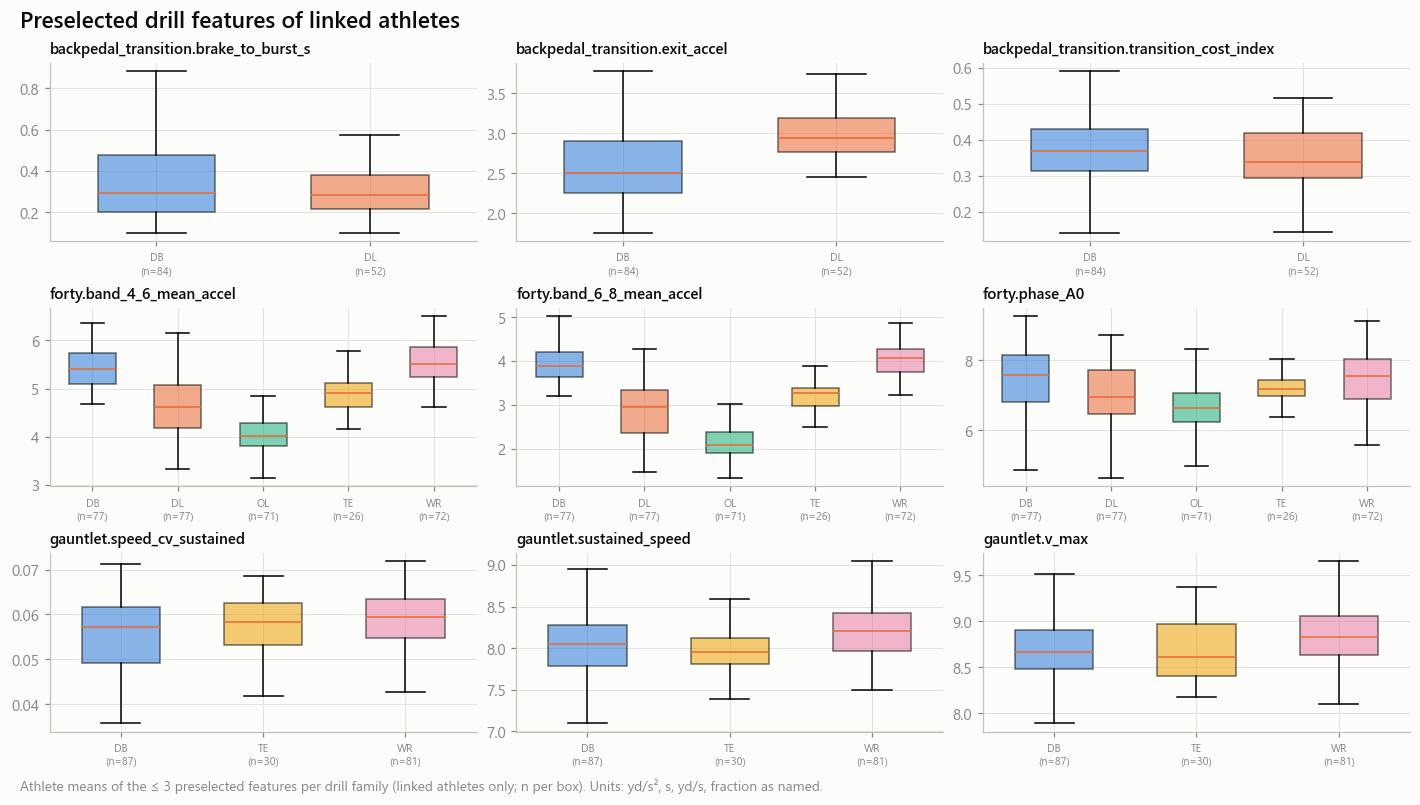

In [4]:
with pl.Config(tbl_rows=-1, tbl_width_chars=220, fmt_str_lengths=60):
    display(pooled)
    display(pl.DataFrame([{'family': f, 'preselected': ', '.join(v)} for f, v in cd.PRESELECTED.items()]))
PRE = [k for v in cd.PRESELECTED.values() for k in v]
long = athf.filter(pl.col('feature').is_in(PRE)).join(data.select('nfl_id', 'position_group'), on='nfl_id', how='inner')
cnt = long.group_by('feature').agg(pl.col('nfl_id').n_unique().alias('n_linked')).sort('feature')
display(cnt)
show = cnt.filter(pl.col('n_linked') >= C.min_athletes_limited)['feature'].to_list()[:9]
store.show(fg.fig_distributions(long, 'feature', 'value', 'position_group', show, 'Preselected drill features of linked athletes',
                                'Athlete means of the ≤ 3 preselected features per drill family (linked athletes only; n per box). Units: yd/s², s, yd/s, fraction as named.'),
           'AM11_A_01_preselected_features', {'preselected_long': long}, publication=False, source='m11_athlete_features')

## 2 · The transfer experiment (all positions pooled)

One row per cell (primary target). `m2_*` = M2 vs M1, `m1_*` = M1 vs M0, `m3_*` = M3 vs M1; `assoc_*` = Spearman of the first preselected feature with the target; `ctrl_*` = controls; `perm_*` = permutation (primary cells). Run time: dominated by the permutation of the ≤ 5 primary cells (`n_perm` refits each).

family,demand_id,target,feasibility,n_athletes,tracking_features,m2_delta_rmse,m2_delta_lo,m2_delta_hi,m2_verdict,assoc_spearman,assoc_lo,assoc_hi,ctrl_random_q95,perm_p,beats_controls,matrix_class
str,str,str,str,i64,str,f64,f64,f64,str,f64,f64,f64,f64,f64,bool,str
"""backpedal_transition""","""accel_low""","""nfl.accel_low_mean""","""UNSUPPORTED""",null,null,null,null,null,null,null,null,null,null,null,null,"""not_tested"""
"""backpedal_transition""","""accel_mid""","""nfl.band_4_6""","""UNSUPPORTED""",null,null,null,null,null,null,null,null,null,null,null,null,"""not_tested"""
"""backpedal_transition""","""braking""","""nfl.brake_decel""","""SUPPORTED""",128,"""backpedal_transition.brake_to_burst_s, backpedal_t…",0.001521,-0.000862,0.004215,"""inconclusive""",0.027457,-0.156983,0.198166,0.002099,null,false,"""no_established_transfer"""
"""backpedal_transition""","""reaccel_after_brake""","""nfl.reaccel_mean""","""SUPPORTED""",112,"""backpedal_transition.brake_to_burst_s, backpedal_t…",0.000535,-0.000799,0.001895,"""inconclusive""",0.009996,-0.181354,0.186032,0.000771,null,false,"""no_established_transfer"""
"""backpedal_transition""","""redirection""","""nfl.redirect_retention""","""SUPPORTED""",104,"""backpedal_transition.brake_to_burst_s, backpedal_t…",-0.000126,-0.001283,0.000901,"""inconclusive""",-0.055788,-0.238677,0.132737,0.001649,null,false,"""no_established_transfer"""
"""backpedal_transition""","""repeated_change""","""""","""UNSUPPORTED""",null,null,null,null,null,null,null,null,null,null,null,null,"""not_tested"""
"""backpedal_transition""","""speed_maintenance""","""""","""UNSUPPORTED""",null,null,null,null,null,null,null,null,null,null,null,null,"""not_tested"""
"""backpedal_transition""","""sustained_high""","""nfl.vmax_p90""","""UNSUPPORTED""",null,null,null,null,null,null,null,null,null,null,null,null,"""not_tested"""
"""backpedal_transition""","""transition_high""","""nfl.band_6_8""","""UNSUPPORTED""",null,null,null,null,null,null,null,null,null,null,null,null,"""not_tested"""


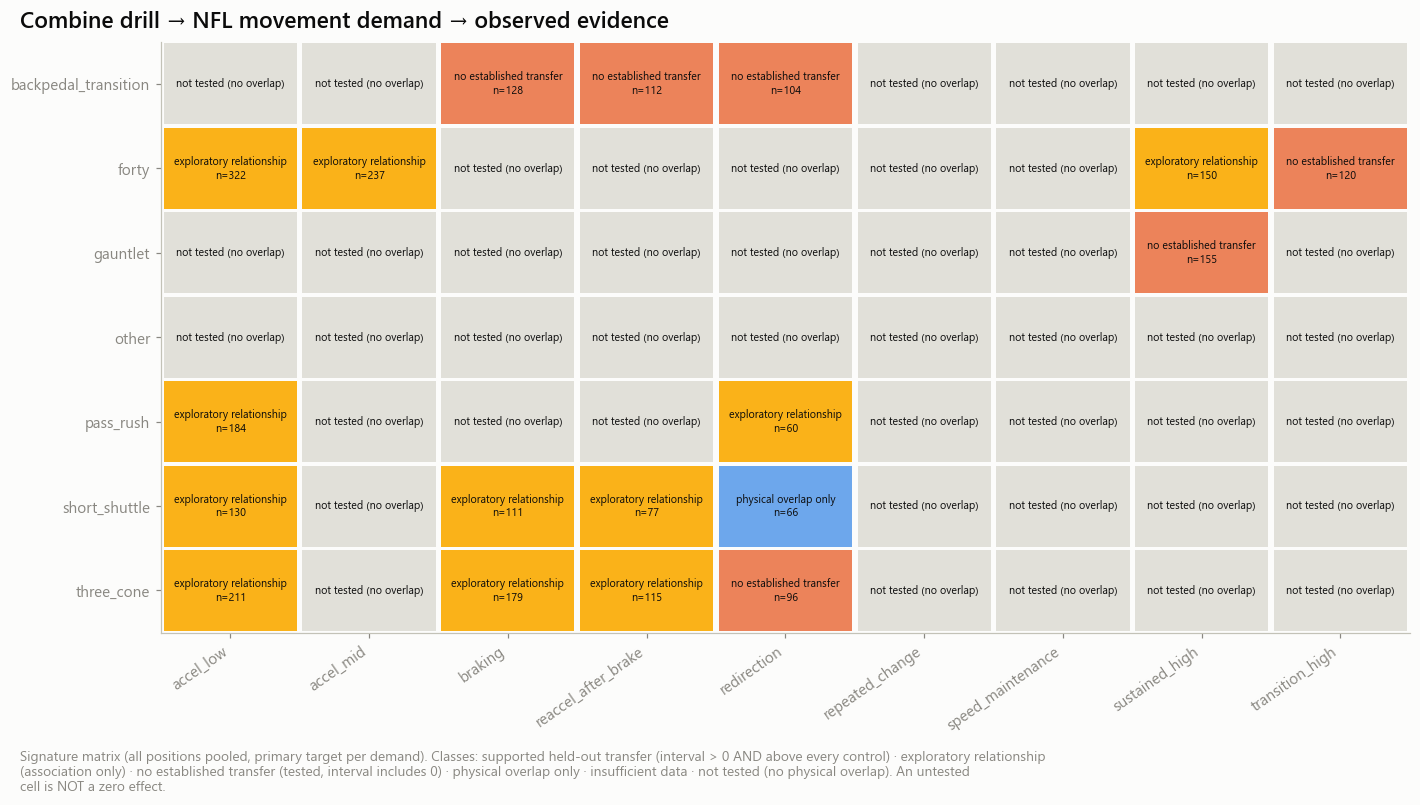

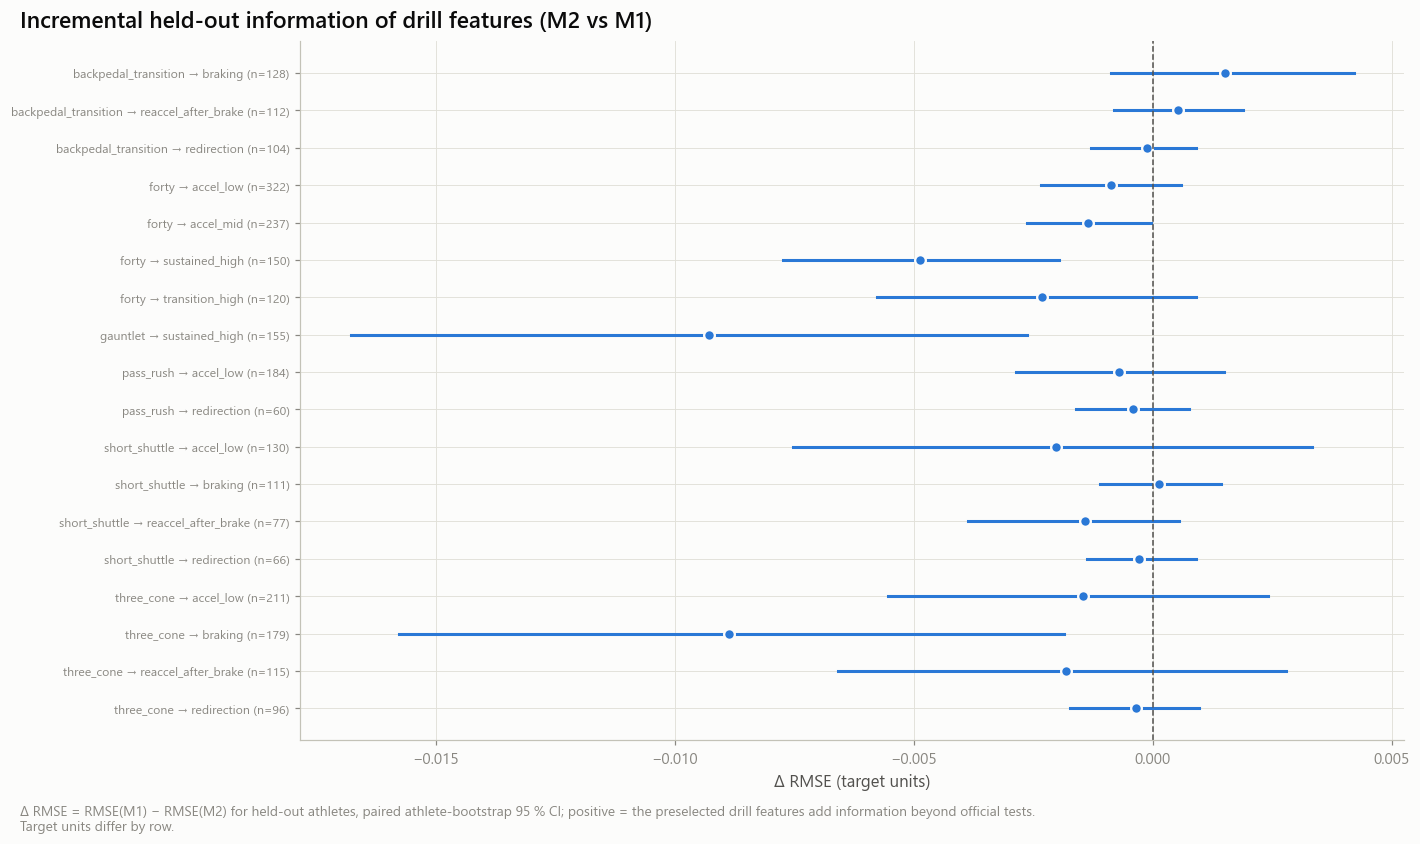

In [5]:
matrix, oof = tm.run_matrix(data, pooled, folds, C, C.seed, all_targets=ALL_TARGETS)
W(matrix, 'm11_transfer_matrix')
W(oof, 'm11_transfer_oof', csv=False)
cols = ['family', 'demand_id', 'target', 'feasibility', 'n_athletes', 'tracking_features', 'm2_delta_rmse', 'm2_delta_lo', 'm2_delta_hi', 'm2_verdict', 'assoc_spearman', 'assoc_lo', 'assoc_hi',
        'ctrl_random_q95', 'perm_p', 'beats_controls', 'matrix_class']
with pl.Config(tbl_rows=-1, tbl_width_chars=300, fmt_str_lengths=50):
    display(matrix.select([c for c in cols if c in matrix.columns]))
mplot = matrix.filter(pl.col('primary_target')).with_columns(
    (pl.col('matrix_class').replace_strict(fg.CLASS_LABELS, default=pl.col('matrix_class')) + pl.when(pl.col('n_athletes').is_not_null()).then(pl.lit('\nn=') + pl.col('n_athletes').cast(pl.String)).otherwise(pl.lit(''))).alias('cell_label'))
store.show(fg.fig_state_grid(mplot, 'family', 'demand_id', 'matrix_class', fg.CLASS_COLORS, 'Combine drill → NFL movement demand → observed evidence',
                             'Signature matrix (all positions pooled, primary target per demand). Classes: supported held-out transfer (interval > 0 AND above every control) · exploratory relationship (association only) · no established transfer (tested, interval includes 0) · physical overlap only · insufficient data · not tested (no physical overlap). An untested cell is NOT a zero effect.',
                             label='cell_label'), 'AM11_A_02_transfer_matrix', {'matrix': mplot}, publication=True, source='m11_transfer_matrix', n=f'{data.height} linked athletes')
comp = matrix.filter(pl.col('status') == 'computed').with_columns((pl.col('family') + ' → ' + pl.col('demand_id') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('cell'))
store.show(fg.fig_forest(comp, 'cell', 'm2_delta_rmse', 'm2_delta_lo', 'm2_delta_hi', 'Incremental held-out information of drill features (M2 vs M1)',
                         'Δ RMSE = RMSE(M1) − RMSE(M2) for held-out athletes, paired athlete-bootstrap 95 % CI; positive = the preselected drill features add information beyond official tests. Target units differ by row.',
                         'Δ RMSE (target units)'), 'AM11_A_03_incremental_forest', {'cells': comp}, publication=True, source='m11_transfer_matrix')

## 3 · Negative controls and exposure sensitivity

Observed Δ RMSE of each SUPPORTED cell beside the Δ of its controls (wrong drill, noncomparable interval) and the 95th percentile of the random-projection control. Exposure: the same cell with athletes having ≥ k target episodes.

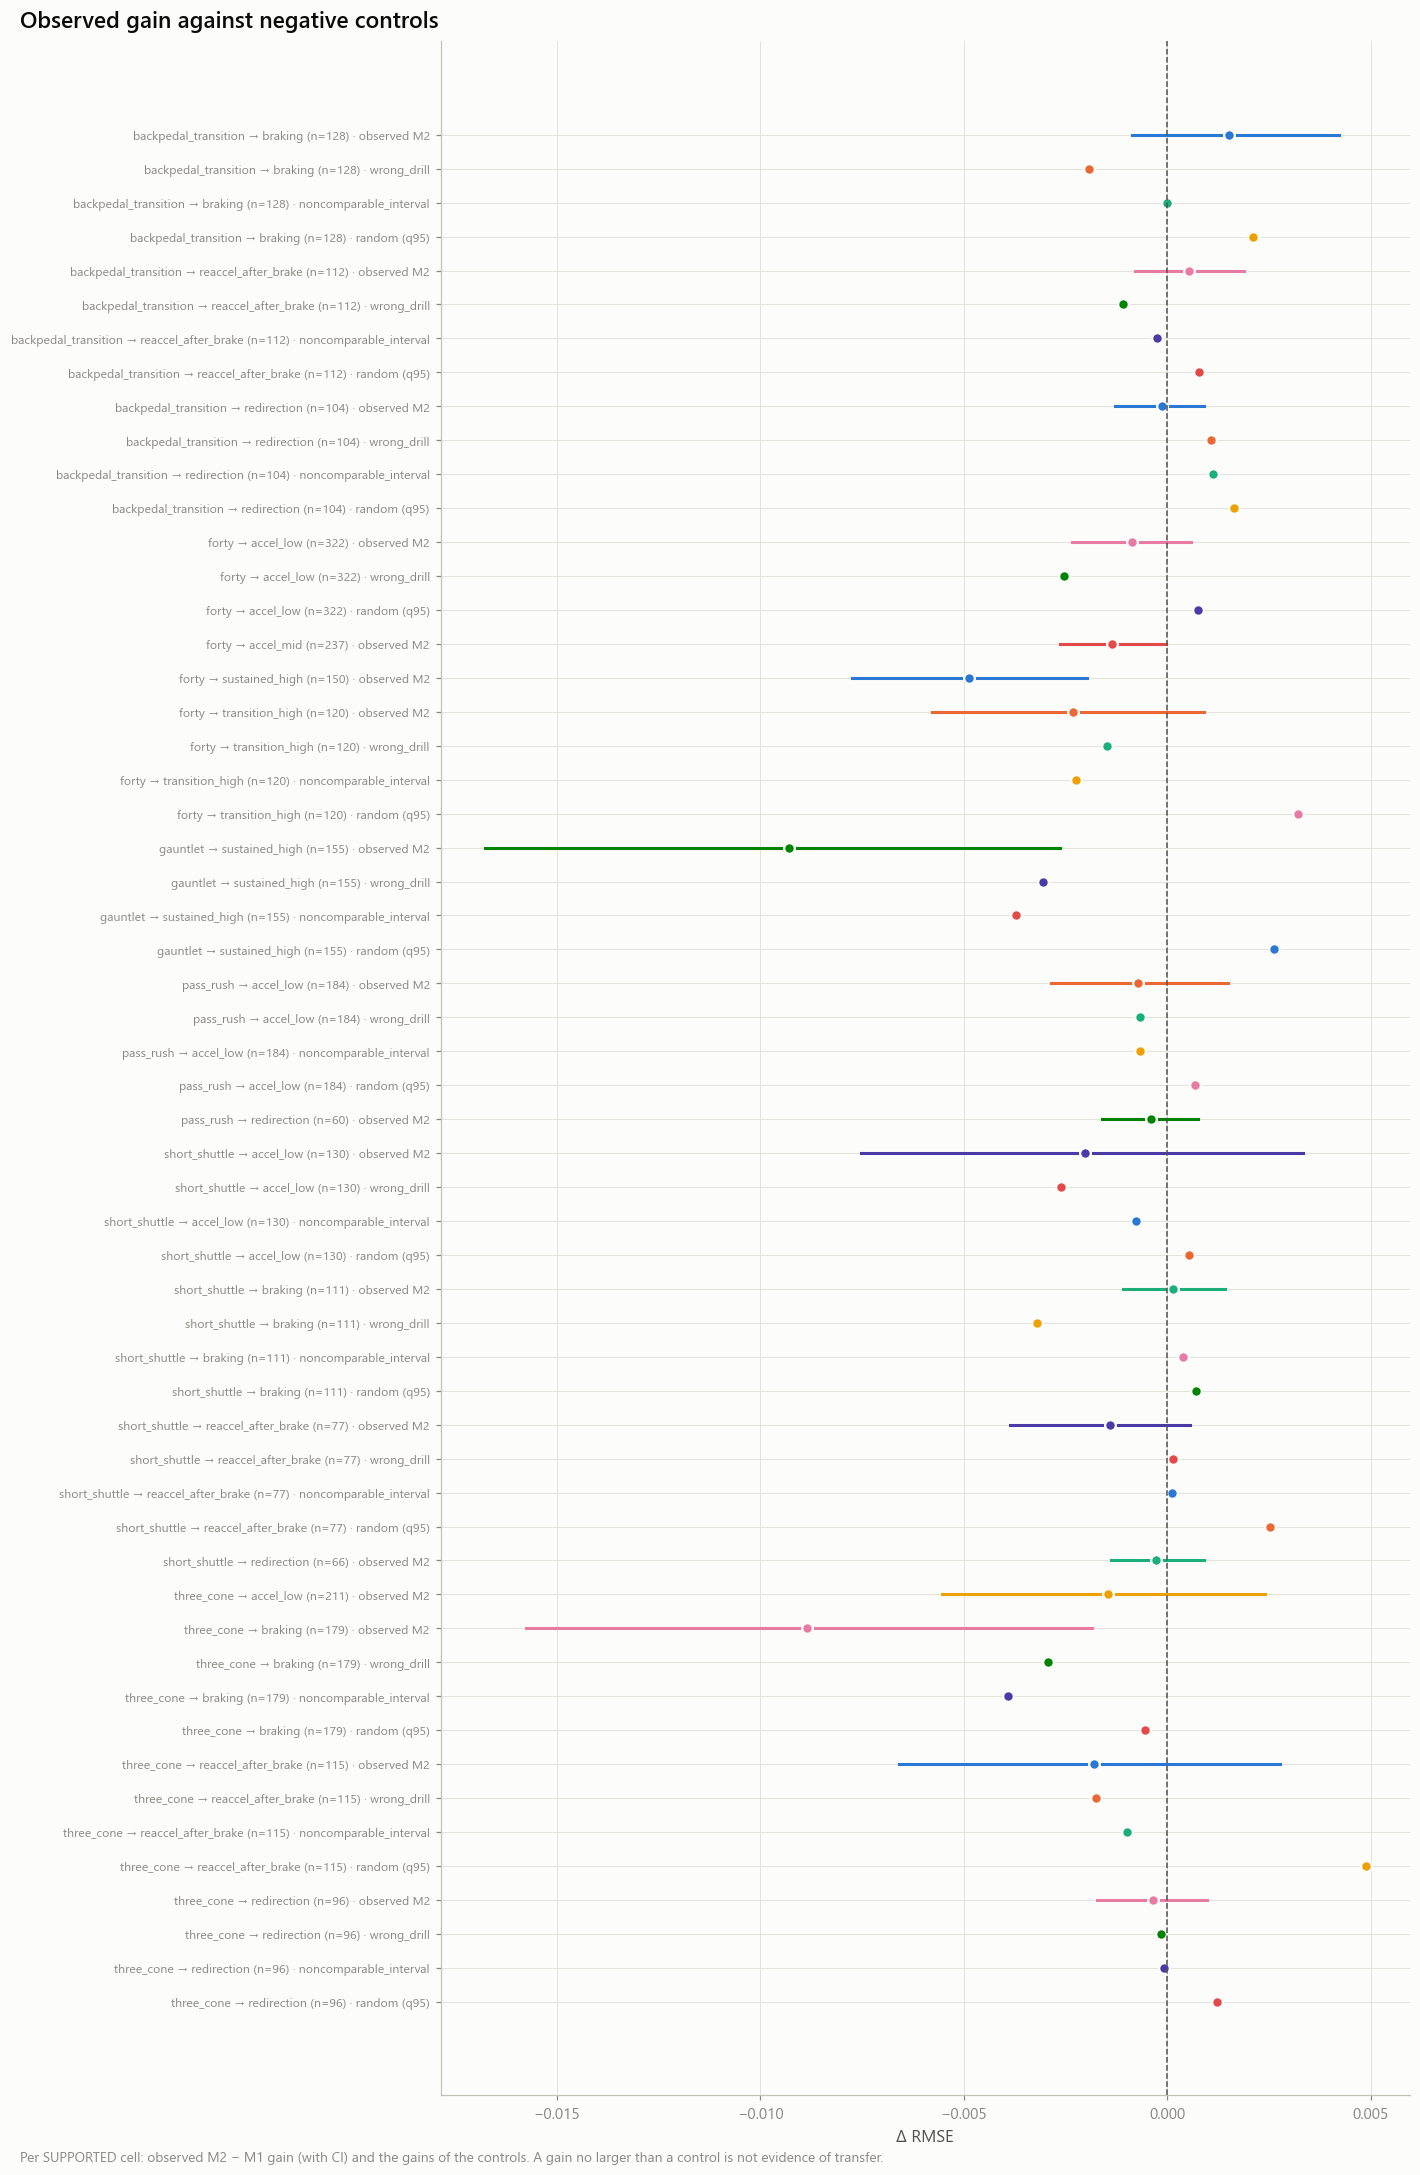

family,demand_id,target,min_episodes,n_athletes,m2_delta_rmse,m2_delta_lo,m2_delta_hi
str,str,str,i64,i64,f64,f64,f64
"""backpedal_transition""","""braking""","""nfl.brake_decel""",10,128,0.001521,-0.000862,0.004215
"""backpedal_transition""","""braking""","""nfl.brake_decel""",25,113,0.001929,-0.000386,0.004652
"""backpedal_transition""","""braking""","""nfl.brake_decel""",50,102,0.004045,-0.000349,0.009787
"""backpedal_transition""","""reaccel_after_brake""","""nfl.reaccel_mean""",10,112,0.000535,-0.000799,0.001895
"""backpedal_transition""","""reaccel_after_brake""","""nfl.reaccel_mean""",25,91,0.000013,-0.000144,0.00019
…,…,…,…,…,…,…,…
"""three_cone""","""reaccel_after_brake""","""nfl.reaccel_mean""",25,75,-0.000666,-0.005461,0.003894
"""three_cone""","""reaccel_after_brake""","""nfl.reaccel_mean""",50,44,0.00939,0.002897,0.017606
"""three_cone""","""redirection""","""nfl.redirect_retention""",10,96,-0.00035,-0.001722,0.000968


In [6]:
ctrl_cols = [c for c in matrix.columns if c.startswith('ctrl_') and c.endswith(('_delta', '_q95'))]
long_ctrl = []
for r in comp.iter_rows(named=True):
    long_ctrl.append({'cell': r['cell'], 'what': 'observed M2', 'delta': r['m2_delta_rmse'], 'lo': r['m2_delta_lo'], 'hi': r['m2_delta_hi']})
    for c in ctrl_cols:
        if r.get(c) is not None:
            long_ctrl.append({'cell': r['cell'], 'what': c.replace('ctrl_', '').replace('_delta', '').replace('_q95', ' (q95)'), 'delta': r[c], 'lo': None, 'hi': None})
LC = pl.DataFrame(long_ctrl, infer_schema_length=None) if long_ctrl else pl.DataFrame()
W(LC, 'm11_transfer_controls')
if LC.height:
    store.show(fg.fig_forest(LC.with_columns((pl.col('cell') + ' · ' + pl.col('what')).alias('label')), 'label', 'delta', 'lo', 'hi', 'Observed gain against negative controls',
                             'Per SUPPORTED cell: observed M2 − M1 gain (with CI) and the gains of the controls. A gain no larger than a control is not evidence of transfer.', 'Δ RMSE', color_by='what'),
               'AM11_A_04_negative_controls', {'controls': LC}, publication=True, source='m11_transfer_matrix')
counts = targets_long.select('nfl_id', 'target_id', 'n_episodes')
expo = tm.exposure_sensitivity(data, counts, matrix, folds, C, C.seed)
W(expo, 'm11_transfer_exposure')
display(expo)

## 4 · Position subgroups

The SUPPORTED cells re-run within positions whose own cell is SUPPORTED (position-level feasibility from 11.0). Position comparisons are exploratory: more tests, fewer athletes.

position_group,family,demand_id,n_athletes,m2_delta_rmse,m2_delta_lo,m2_delta_hi,matrix_class
str,str,str,i64,f64,f64,f64,str
"""DB""","""forty""","""accel_low""",77,-0.000239,-0.002257,0.002315,"""no_established_transfer"""
"""DB""","""gauntlet""","""sustained_high""",68,-0.000248,-0.00831,0.00724,"""no_established_transfer"""
"""DB""","""backpedal_transition""","""braking""",80,0.001236,-0.001343,0.004053,"""no_established_transfer"""
"""DB""","""backpedal_transition""","""reaccel_after_brake""",70,-0.000214,-0.000475,0.000044,"""no_established_transfer"""
"""DB""","""backpedal_transition""","""redirection""",69,-0.001452,-0.003632,0.001134,"""no_established_transfer"""
…,…,…,…,…,…,…,…
"""OL""","""short_shuttle""","""braking""",30,-0.00014,-0.000566,0.00029,"""no_established_transfer"""
"""OL""","""three_cone""","""braking""",59,0.002047,-0.007875,0.012836,"""no_established_transfer"""
"""OL""","""pass_rush""","""accel_low""",86,-0.000261,-0.004864,0.004118,"""no_established_transfer"""


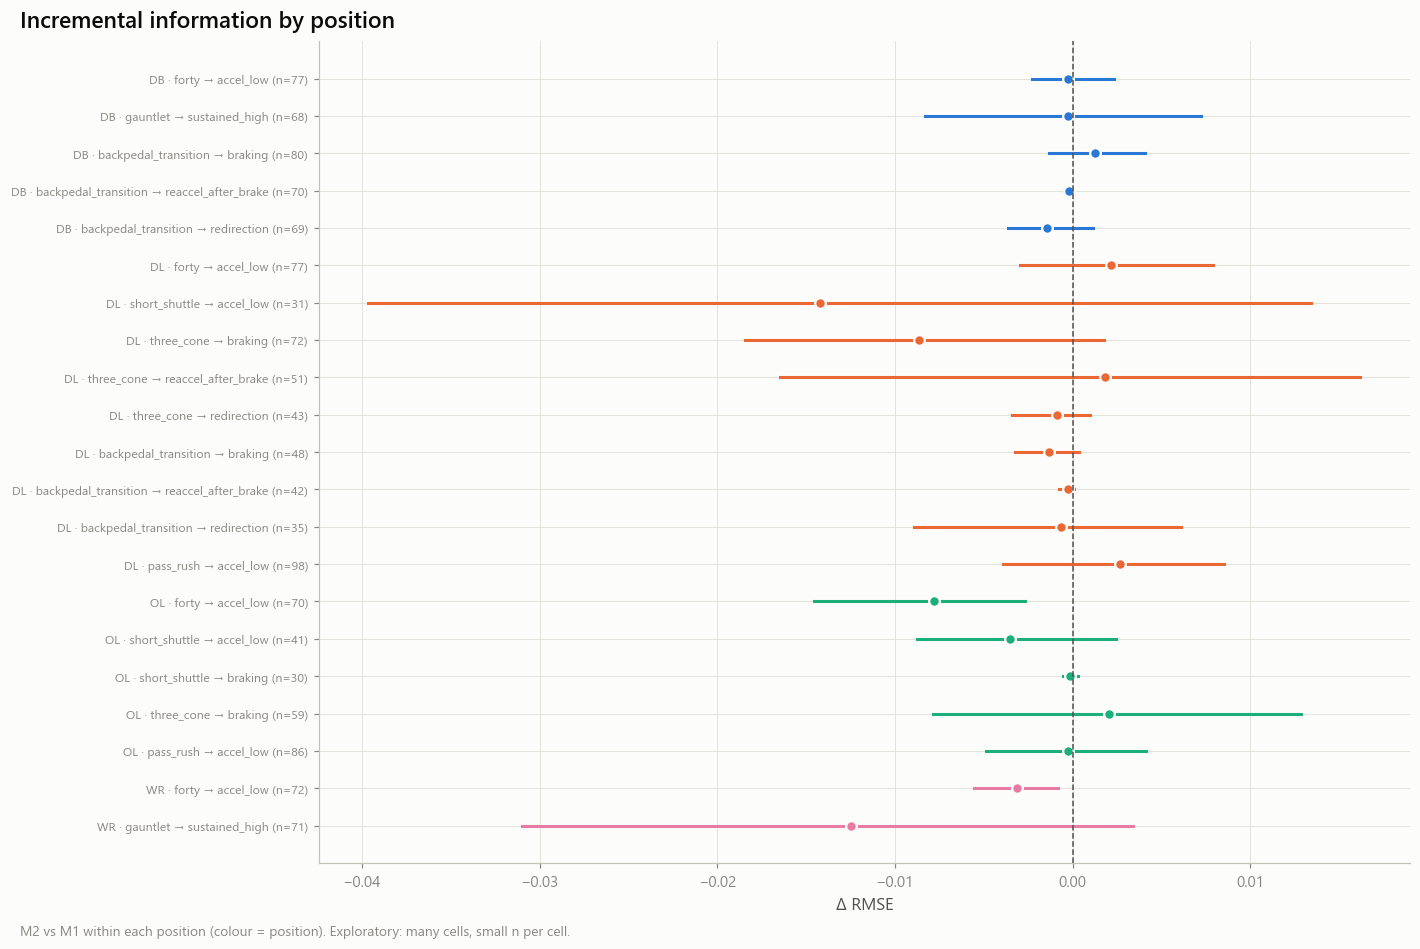

In [7]:
parts = []
if BY_POSITION:
    for (pos,), fpos in sorted(fm.filter(pl.col('feasibility') == m11c.SUPPORTED).partition_by(['position_group'], as_dict=True).items()):
        mask = (data['position_group'] == pos).to_numpy()
        if mask.sum() < C.min_athletes_cell:
            continue
        mp, _ = tm.run_matrix(data.filter(pl.Series(mask)), fpos, folds[mask], C, C.seed)
        parts.append(mp.with_columns(pl.lit(pos).alias('position_group')))
bypos = pl.concat(parts, how='diagonal_relaxed') if parts else pl.DataFrame()
W(bypos, 'm11_transfer_matrix_by_position')
if bypos.height:
    bp = bypos.filter(pl.col('status') == 'computed').with_columns((pl.col('position_group') + ' · ' + pl.col('family') + ' → ' + pl.col('demand_id') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('cell'))
    display(bp.select('position_group', 'family', 'demand_id', 'n_athletes', 'm2_delta_rmse', 'm2_delta_lo', 'm2_delta_hi', 'matrix_class'))
    store.show(fg.fig_forest(bp, 'cell', 'm2_delta_rmse', 'm2_delta_lo', 'm2_delta_hi', 'Incremental information by position',
                             'M2 vs M1 within each position (colour = position). Exploratory: many cells, small n per cell.', 'Δ RMSE', color_by='position_group'),
               'AM11_A_05_by_position', {'by_position': bp}, publication=False, source='m11_transfer_matrix_by_position')

## 5 · Metric evidence and conclusion

## 11A — conclusion (inconclusive; run mode full; generated 2026-10-14T22:40:51Z)

### Research question
Do drill-specific movement features add held-out information on physically comparable NFL movement?

### Hypothesis
For SUPPORTED drill × demand cells, M2 (official + ≤ 3 preselected tracking features) lowers held-out RMSE vs M1.

### Sample
387 linked athletes; 18 cells computed; positions DB, DL, OL, TE, WR.

### Main evidence
- not_tested: 45 cells
- exploratory_statistical_relationship: 11 cells
- no_established_transfer: 6 cells
- established_physical_overlap: 1 cells
- forty → accel_low (nfl.accel_low_mean): Δ RMSE -0.0009 [-0.0023, 0.0006], n=322, controls beaten: False, permutation p 0.657
- pass_rush → accel_low (nfl.accel_low_mean): Δ RMSE -0.0007 [-0.0029, 0.0015], n=184, controls beaten: False, permutation p 0.413
- short_shuttle → braking (nfl.brake_decel): Δ RMSE 0.0001 [-0.0011, 0.0014], n=111, controls beaten: False, permutation p 0.483
- short_shuttle → reaccel_after_brake (nfl.reaccel_mean): Δ RMSE -0.0014 [-0.0039, 0.0006], n=77, controls beaten: False, permutation p 0.811
- three_cone → redirection (nfl.redirect_retention): Δ RMSE -0.0003 [-0.0017, 0.0010], n=96, controls beaten: False, permutation p 0.458

### Alternative explanations
- Drill participation is selected; complete-case cells describe tracked athletes only.
- Official drill times absorb much of a drill’s information; M2 measures what remains.
- Targets mix athlete and role: a gain may reflect position usage rather than capacity.

### Practical scouting relevance
Shows which drills add measurable, held-out information about physically matched game movement — and which only overlap physically.

### Limitations
- Many cells: classes other than the declared primary cells are exploratory.
- Small linked cohorts give wide intervals: inconclusive ≠ no effect (see mde in 11B / 11C).

### Next experiment
- Freeze any supported cell as a confirmatory hypothesis for a later draft class.
- Use 11G to decide which drills to keep tracking.


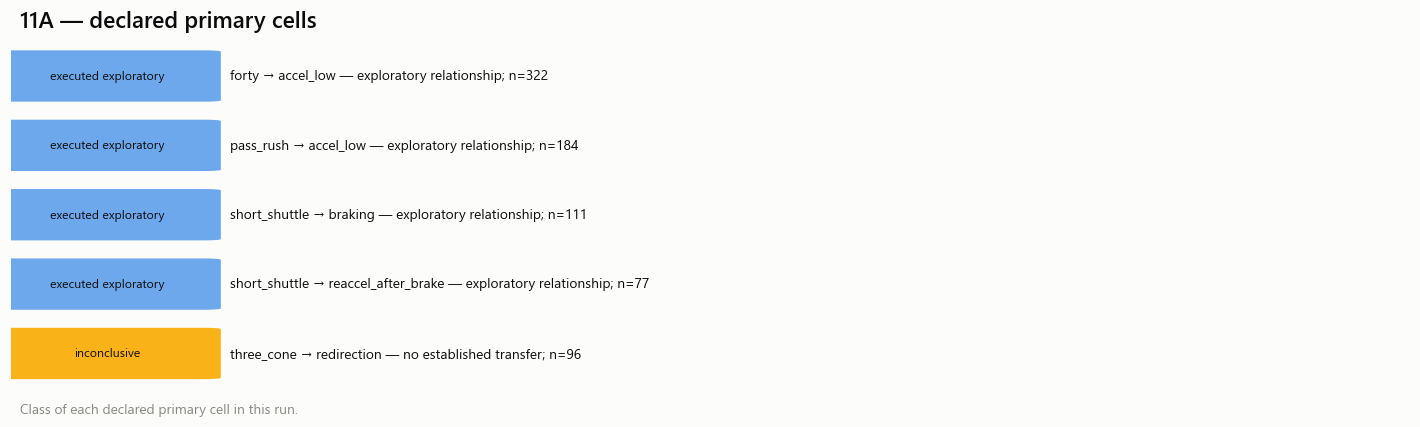

Send back: the matrix table, figures AM11_A_02 / 03 / 04, the exposure table, and the conclusion.
Next: 11e_stopwatch_twin_discordance.ipynb


In [8]:
evid = []
for r in comp.iter_rows(named=True):
    evid.append(tn.evidence_row(f"family.{r['family']}", '11A', n_athletes=r['n_athletes'], nfl_comparison=r['target'], delta_rmse=r['m2_delta_rmse'], delta_lo=r['m2_delta_lo'],
                                delta_hi=r['m2_delta_hi'], beats_controls=r.get('beats_controls'), execution_mode=controls.run_mode, config_hash=C.hash(), note=f"{r['demand_id']}: {r['tracking_features']}"))
W(tn.evidence_frame(evid), 'm11_metric_evidence_11A')
classes = matrix.filter(pl.col('primary_target')).group_by('matrix_class').len().sort('len', descending=True)
prim = matrix.filter(pl.col('primary_cell').fill_null(False))
status = rp.comparison_status([('model_better' if r['matrix_class'] == m11c.SUPPORTED_TRANSFER else r.get('m2_verdict')) for r in prim.iter_rows(named=True)], computed=bool(comp.height))
facts = {'status': status, 'run_mode': controls.run_mode,
         'sample': f"{data.height} linked athletes; {comp.height} cells computed; positions {', '.join(sorted(data['position_group'].drop_nulls().unique().to_list()))}.",
         'evidence': [f"{r['matrix_class']}: {r['len']} cells" for r in classes.iter_rows(named=True)]
                     + [f"{r['family']} → {r['demand_id']} ({r['target']}): Δ RMSE {rp.ci(r['m2_delta_rmse'], r['m2_delta_lo'], r['m2_delta_hi'], 4)}, n={r['n_athletes']}, controls beaten: {r.get('beats_controls')}, permutation p {rp.fmt(r.get('perm_p'))}" for r in prim.iter_rows(named=True)],
         'alternatives': ['Drill participation is selected; complete-case cells describe tracked athletes only.', 'Official drill times absorb much of a drill’s information; M2 measures what remains.',
                          'Targets mix athlete and role: a gain may reflect position usage rather than capacity.'],
         'relevance': 'Shows which drills add measurable, held-out information about physically matched game movement — and which only overlap physically.',
         'limitations': ['Many cells: classes other than the declared primary cells are exploratory.', 'Small linked cohorts give wide intervals: inconclusive ≠ no effect (see mde in 11B / 11C).'],
         'next': ['Freeze any supported cell as a confirmatory hypothesis for a later draft class.', 'Use 11G to decide which drills to keep tracking.']}
md_ = rp.conclusion_markdown('11A', facts)
display(Markdown(md_))
rp.write_conclusion(store, '11A', md_)
rp.run_manifest(store, '11A', PROV, ['m11_transfer_matrix', 'm11_transfer_controls', 'm11_transfer_exposure', 'm11_metric_evidence_11A'], status)
crow = pl.DataFrame([{'item': f"{r['family']} → {r['demand_id']}", 'evidence': f"{fg.CLASS_LABELS.get(r['matrix_class'], r['matrix_class'])}; n={r.get('n_athletes')}",
                      'status': {m11c.SUPPORTED_TRANSFER: 'supported_finding', m11c.NO_ESTABLISHED_TRANSFER: 'inconclusive', m11c.INSUFFICIENT_DATA: 'not_feasible'}.get(r['matrix_class'], 'executed_exploratory')}
                     for r in prim.iter_rows(named=True)])
store.show(fg.fig_conclusion(crow, '11A — declared primary cells', 'Class of each declared primary cell in this run.'), 'AM11_A_06_conclusion', {}, publication=True, source='m11_transfer_matrix')
print('Send back: the matrix table, figures AM11_A_02 / 03 / 04, the exposure table, and the conclusion.')
print('Next: 11e_stopwatch_twin_discordance.ipynb')